In [1]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (f1_score, accuracy_score, precision_score)
from sklearn.metrics import (recall_score, classification_report, confusion_matrix)
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score)

from sklearn.base import clone

random_state = 42

In [2]:
cv_splits = 5

training_data = pd.read_csv("../dataset/task1_static/train_features.csv")
training_labels = pd.read_csv("../dataset/task1_static/train_labels.csv")
training_data = training_data.merge(training_labels, left_on="flow_id", right_on="flow_id")

validation_data = pd.read_csv("../dataset/task1_static/validation_features.csv")
validation_labels = pd.read_csv("../dataset/task1_static/validation_labels.csv")
validation_data = validation_data.merge(validation_labels, left_on="flow_id", right_on="flow_id")

In [3]:
cv_splits = 5

selected_features = ['transport', 'start_rel', 'duration', 'server_port', 'packet_count_down', 'bytes_up', 'mean_pkt_size_up', 'mean_pkt_size_down', 
                     'std_pkt_size_up', 'std_pkt_size_down', 'mean_iat', 'std_iat', 'min_iat', 'max_iat', 'up_down_packet_ratio', 'up_down_byte_ratio']

low_association_features = ['std_pkt_size_down', 'up_down_byte_ratio', 'mean_iat',
                            'std_iat', 'min_iat', 'max_iat', 'server_port']

# set(selected_features) - set(low_assoiation_features)
reduced_features = [f for f in selected_features if f not in low_association_features]

skewed_features = ['min_iat', 'packet_count_down', 'up_down_byte_ratio', 'bytes_up', 'mean_iat',
                   'duration', 'std_iat', 'max_iat', 'mean_pkt_size_up']

# throughput style features (same as 10_google_youtube_confusion)
def add_rate_features(df):
    return df

training_data = add_rate_features(training_data)
validation_data = add_rate_features(validation_data)

X_train = training_data[selected_features].copy()
y_train = training_data["app"].copy()
X_val = validation_data[selected_features].copy()
y_val = validation_data["app"].copy()

def preprocess_data(X, log_features=[]):
    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = X.select_dtypes(exclude=np.number).columns.tolist()
    log_cols = [c for c in numeric if c in log_features]
    numeric = [c for c in numeric if c not in log_features]
    numeric_pipe = Pipeline([('scaler', StandardScaler())])
    categorical_pipe = Pipeline([('onehot', OneHotEncoder())])
    log_pipe = Pipeline([('log', FunctionTransformer(np.log1p)), ('scaler', StandardScaler())])
    return ColumnTransformer([('numeric', numeric_pipe, numeric),
                              ('categorical', categorical_pipe, categorical),
                              ('log', log_pipe, log_cols)])

def report(search, Xtr, ytr, Xte, yte, experiment_name, tie_tolerance=1e-6):

    start = time.time()
    search.fit(Xtr, ytr)
    elapsed = time.time() - start
    cv_results = pd.DataFrame(search.cv_results_)
    max_score = cv_results["mean_test_score"].max()

    tied = cv_results[np.isclose(cv_results["mean_test_score"], max_score, rtol=0, atol=tie_tolerance)].copy()

    print("\n" + "=" * 60)
    print(f"Experiment: {experiment_name}")
    print("=" * 60)

    print("Maximum CV Macro-F1:", max_score)
    print("Number of tied configurations:", len(tied))

    # Occasors rule: Tie-breaking based on Decision Tree simplicity
    def get_param(params, name, default=None):
        for key, value in params.items():
            if key.endswith(name):
                return value
        return default

    def depth_key(params):
        depth = get_param(params, "max_depth")
        return np.inf if depth is None else depth

    def leaf_key(params):
        return -get_param(params, "min_samples_leaf", 1)

    def split_key(params):
        return -get_param(params, "min_samples_split", 2)

    tied["depth_sort"] = tied["params"].apply(depth_key)
    tied["leaf_sort"] = tied["params"].apply(leaf_key)
    tied["split_sort"] = tied["params"].apply(split_key)

    # Preferring:
    # 1. Smaller max_depth
    # 2. Larger min_samples_leaf
    # 3. Larger min_samples_split

    tied = tied.sort_values(by=["depth_sort", "leaf_sort", "split_sort"], ascending=True)
    
    selected_params = tied.iloc[0]["params"]
    selected_cv_score = tied.iloc[0]["mean_test_score"]

    print("\nTie-breaking selection:")
    print("Selected parameters:", selected_params)
    print("Selected CV Macro-F1:", selected_cv_score)

    print("\nAll tied configurations:")
    print(tied[["params", "mean_test_score", "std_test_score"]].to_string(index=False))

    # 4. Refit the selected simplest configuration
    selected_model = clone(search.estimator)
    selected_model.set_params(**selected_params)
    selected_model.fit(Xtr, ytr)

    # Update search object to reflect tie-break selection
    search.best_index_ = int(tied.index[0])
    search.best_params_ = selected_params
    search.best_score_ = selected_cv_score
    search.best_estimator_ = selected_model

    pred = selected_model.predict(Xte)

    test_f1 = f1_score(yte, pred, average="macro")
    test_accuracy = accuracy_score(yte, pred)

    print("\nFinal Selected Model")
    print("-" * 40)
    print("Selected CV Macro-F1:", selected_cv_score)
    print("Selected parameters:", selected_params)
    print("Test Macro-F1:", test_f1)
    print("Test Accuracy:", test_accuracy)

    print("\nClassification Report:")
    print(classification_report(yte, pred, zero_division=0))

    labels = selected_model.classes_

    cm = confusion_matrix(yte, pred, labels=labels)

    plt.figure(figsize=(10, 8))

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels    )

    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(f'Confusion Matrix - {experiment_name}')

    plt.tight_layout()
    plt.show()

    cv_results["experiment"] = experiment_name
    cv_results["elapsed_seconds_search"] = elapsed

    cv_results.to_csv(f'{experiment_name.lower().replace(" ", "_")}_all_cv_results.csv',index=False)

    # Save tied configurations
    tied.to_csv(f'{experiment_name.lower().replace(" ", "_")}_tied_best_configs.csv', index=False)

    evaluation = pd.DataFrame([{
        "Experiment": experiment_name,
        "Selected_CV_MacroF1": selected_cv_score,
        "Test_MacroF1": test_f1,
        "Test_Accuracy": test_accuracy,
        "Selected_Params": str(selected_params),
        "Number_of_Tied_Configurations": len(tied),
        "Elapsed_Seconds": elapsed
    }])
    
    evaluation.to_csv(f'{experiment_name.lower().replace(" ", "_")}_final_report.csv', index=False)
    return search, cv_results, pred

def run_experiment(model, param_grid, model_name, feature_list, log_features=[], tag=None):
    Xtr, Xte = X_train[feature_list].copy(), X_val[feature_list].copy()
    pipe = Pipeline([('preprocess', preprocess_data(Xtr, log_features)), ('model', model)])
    grid = {'model__' + k: v for k, v in param_grid.items()}
    search = GridSearchCV(pipe, grid, scoring='f1_macro', cv=cv, n_jobs=-1, refit=True, return_train_score=True, verbose=1)
    if tag is None:
        tag = '_E1_16features' if len(feature_list)==16 else '_E2_reduced'
    experiment_name = model_name + tag
    return report(search, Xtr, y_train, Xte, y_val, experiment_name)

def evaluate(model, Xte, yte):
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)
    return {"Accuracy": accuracy_score(yte, pred),
            "Balanced_Accuracy": balanced_accuracy_score(yte, pred),
            "F1_weighted": f1_score(yte, pred, average='weighted'),
            "Macro_F1": f1_score(yte, pred, average='macro'),
            "AUC_ROC": roc_auc_score(yte, proba, multi_class='ovr')}

### Model and tuning space

In [4]:
cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=random_state)

param_grid = {
    'criterion': ['gini', 'entropy'], 
    'max_depth': [None, 5, 10, 15, 20, 30], 
    'min_samples_split': [2, 5, 10, 15, 20], 
    'min_samples_leaf': [1, 2, 5, 7, 10], 
    'class_weight': [None, 'balanced']
}

### Experiment-1: All 16 selected features

In [5]:
model_e1 = DecisionTreeClassifier(random_state=random_state)

Fitting 5 folds for each of 600 candidates, totalling 3000 fits



Experiment: decision_tree_E1_16features
Maximum CV Macro-F1: 0.6125517649767213
Number of tied configurations: 4

Tie-breaking selection:
Selected parameters: {'model__class_weight': 'balanced', 'model__criterion': 'gini', 'model__max_depth': 15, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Selected CV Macro-F1: 0.6125517649767213

All tied configurations:
                                                                                                                                                params  mean_test_score  std_test_score
  {'model__class_weight': 'balanced', 'model__criterion': 'gini', 'model__max_depth': 15, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}         0.612552        0.089868
  {'model__class_weight': 'balanced', 'model__criterion': 'gini', 'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}         0.612552        0.089868
  {'model__class_weight': 'balanced', 'model__criterion': 'gini', 'model

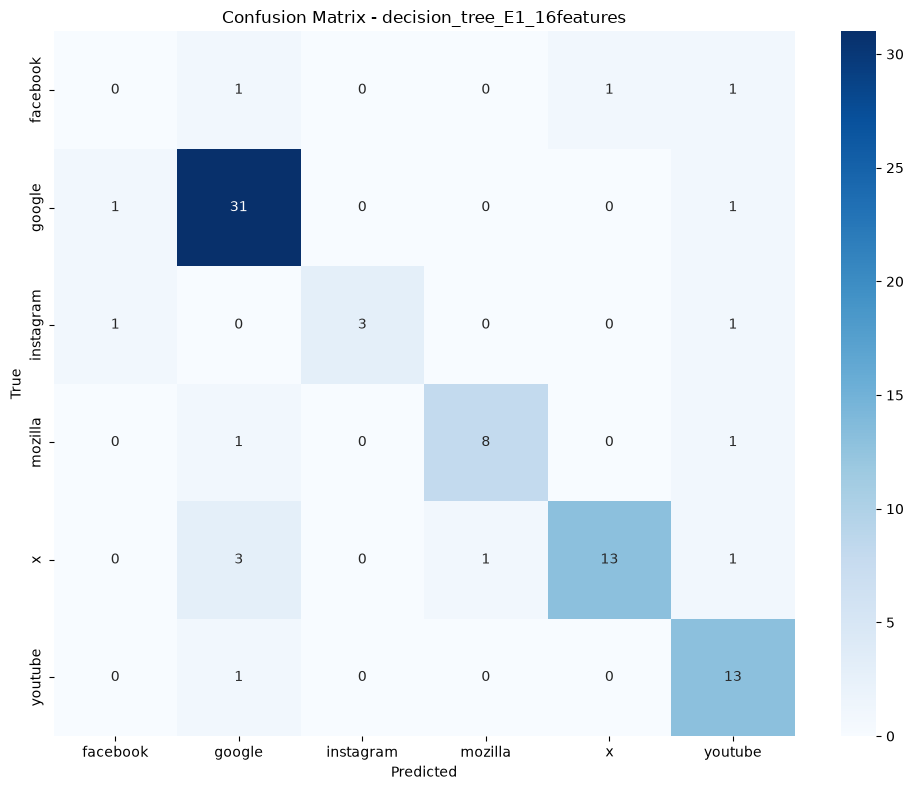

In [6]:
search_e1, results_e1, pred_e1 = run_experiment(model_e1, param_grid, 'decision_tree', selected_features)

### Experiment-2: Reduced feature set (9 features)arol

In [7]:
model_e2 = DecisionTreeClassifier(random_state=random_state)

Fitting 5 folds for each of 600 candidates, totalling 3000 fits



Experiment: decision_tree_E2_reduced
Maximum CV Macro-F1: 0.5600582258012599
Number of tied configurations: 5

Tie-breaking selection:
Selected parameters: {'model__class_weight': None, 'model__criterion': 'entropy', 'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Selected CV Macro-F1: 0.5600582258012599

All tied configurations:
                                                                                                                                             params  mean_test_score  std_test_score
  {'model__class_weight': None, 'model__criterion': 'entropy', 'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}         0.560058        0.070541
  {'model__class_weight': None, 'model__criterion': 'entropy', 'model__max_depth': 15, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}         0.560058        0.070541
  {'model__class_weight': None, 'model__criterion': 'entropy', 'model__max_depth': 20, 

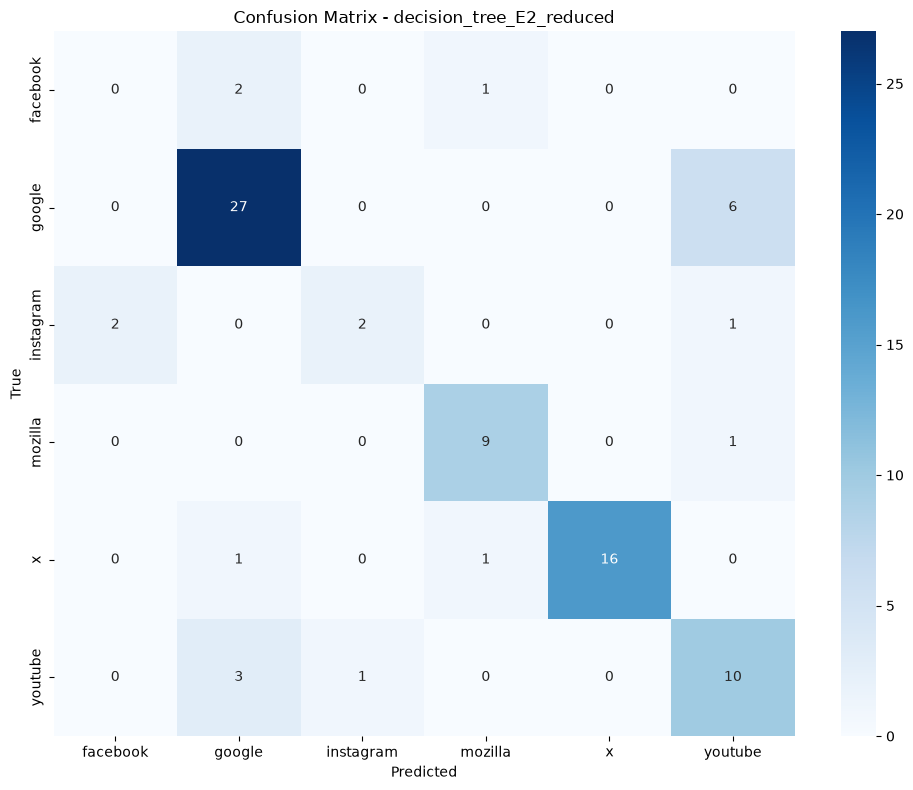

In [8]:
search_e2, results_e2, pred_e2 = run_experiment(model_e2, param_grid, 'decision_tree', reduced_features)

### Experiment-3: Log-transform of the skewed features (16 features)

Fitting 5 folds for each of 600 candidates, totalling 3000 fits

Experiment: decision_tree_E3_log
Maximum CV Macro-F1: 0.5961711081787973
Number of tied configurations: 4

Tie-breaking selection:
Selected parameters: {'model__class_weight': 'balanced', 'model__criterion': 'gini', 'model__max_depth': 15, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Selected CV Macro-F1: 0.5961711081787973

All tied configurations:
                                                                                                                                                params  mean_test_score  std_test_score
  {'model__class_weight': 'balanced', 'model__criterion': 'gini', 'model__max_depth': 15, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}         0.596171        0.080351
  {'model__class_weight': 'balanced', 'model__criterion': 'gini', 'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}         0.596171        0.080351
  {'model__clas

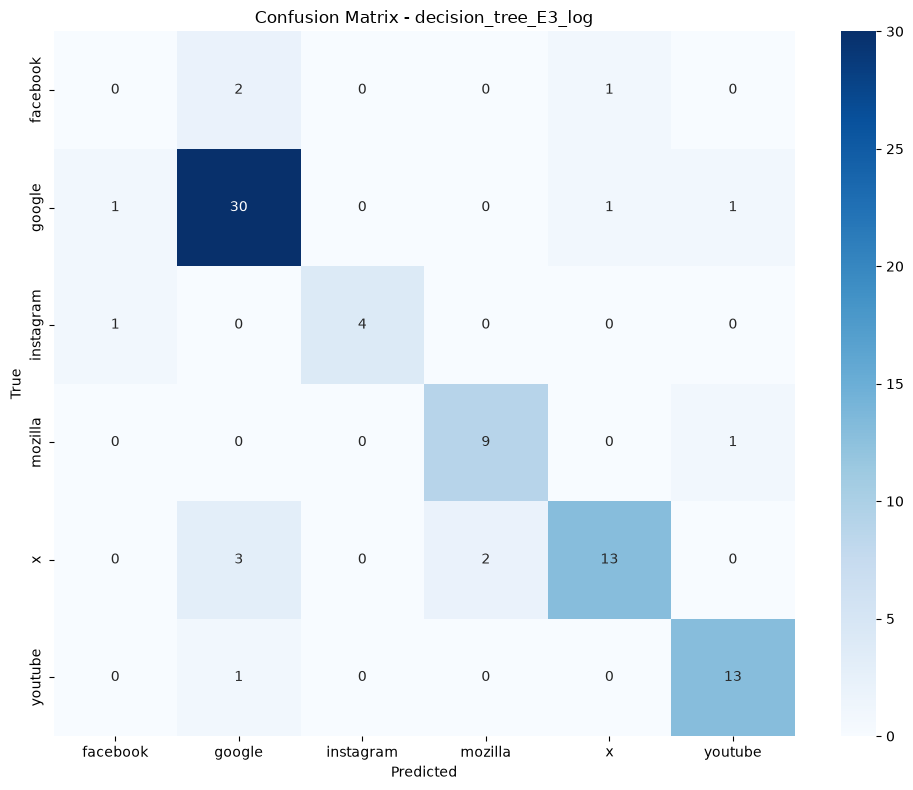

In [9]:
model_e3 = DecisionTreeClassifier(random_state=random_state)
search_e3, results_e3, pred_e3 = run_experiment(model_e3, param_grid, 'decision_tree', selected_features,
                                                log_features=skewed_features, tag='_E3_log')

### Compare feature configurations

In [10]:
experiments = {"E1_16feat": (search_e1, selected_features),
               "E2_reduced_feat": (search_e2, reduced_features),
               "E3_log": (search_e3, selected_features)}

comparision = []
for name, (search, feats) in experiments.items():
    row = {"Experiment": name, "Best_CV_MacroF1": search.best_score_}
    row.update(evaluate(search.best_estimator_, X_val[feats], y_val))
    comparision.append(row)
comparision = pd.DataFrame(comparision)
display(comparision.round(4))
comparision.to_csv('feature_ablation_comparison_decision_tree.csv', index=False)

,Experiment,Best_CV_MacroF1,Accuracy,Balanced_Accuracy,F1_weighted,Macro_F1,AUC_ROC
0,E1_16feat,0.6126,0.8193,0.6650,0.8120,0.6838,0.8120
1,E2_reduced_feat,0.5601,0.7711,0.6202,0.7682,0.6236,0.7850
2,E3_log,0.5962,0.8313,0.7100,0.8246,0.7167,0.8356


In [13]:
from lime.lime_tabular import LimeTabularExplainer
from sklearn.preprocessing import LabelEncoder

feature_names = selected_features
pipeline_e1 = search_e1.best_estimator_

cat_cols = X_train[feature_names].select_dtypes(exclude=np.number).columns.tolist()
cat_idx = [feature_names.index(c) for c in cat_cols]

X_train_enc = X_train[feature_names].copy()
X_val_enc = X_val[feature_names].copy()
label_encoders, categorical_names = {}, {}

for c in cat_cols:
    le = LabelEncoder()
    X_train_enc[c] = le.fit_transform(X_train_enc[c].astype(str))
    X_val_enc[c] = X_val_enc[c].astype(str).map(
        lambda v: le.transform([v])[0] if v in le.classes_ else -1
    )
    label_encoders[c] = le
    categorical_names[feature_names.index(c)] = list(le.classes_)

explainer = LimeTabularExplainer(
    training_data=X_train_enc.values,
    feature_names=feature_names,
    class_names=[str(c) for c in pipeline_e1.classes_],
    categorical_features=cat_idx,
    categorical_names=categorical_names,
    mode='classification',
    discretize_continuous=True,
    random_state=random_state,
)

def predict_fn(data):
    df = pd.DataFrame(data, columns=feature_names)
    for c in cat_cols:
        le = label_encoders[c]
        codes = df[c].round().astype(int).clip(0, len(le.classes_) - 1)
        df[c] = le.inverse_transform(codes)
    return pipeline_e1.predict_proba(df)

n_val = len(X_val_enc)
importance_sum = np.zeros(len(feature_names))

for i in range(n_val):
    instance = X_val_enc.iloc[i].values
    exp = explainer.explain_instance(instance, predict_fn, num_features=len(feature_names), top_labels=1)
    label = exp.available_labels()[0]
    for feat_idx, weight in exp.local_exp[label]:
        importance_sum[feat_idx] += abs(weight)

lime_scores_e1 = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_lime_weight": importance_sum / n_val
}).sort_values("mean_abs_lime_weight", ascending=False).reset_index(drop=True)

print(lime_scores_e1)
lime_scores_e1.to_csv("lime_scores_experiment1.csv", index=False)

                 feature  mean_abs_lime_weight
0              start_rel              0.077708
1               bytes_up              0.068712
2              transport              0.068537
3       mean_pkt_size_up              0.055574
4     mean_pkt_size_down              0.055089
5      packet_count_down              0.051289
6                min_iat              0.047195
7               duration              0.045159
8                max_iat              0.043212
9        std_pkt_size_up              0.039519
10  up_down_packet_ratio              0.030465
11    up_down_byte_ratio              0.028361
12              mean_iat              0.018471
13     std_pkt_size_down              0.013105
14               std_iat              0.011066
15           server_port              0.000000


In [12]:
%pip install lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached lazy_loader-0.6-py3-none-any.whl.metadata (6.0 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.7/13.7 MB 44.8 MB/s  0:00:00eta 0:00:01
Using cached lazy_loader-0.6-py3-none-any.whl (8.8 kB)
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=f253a1bbfc331776a2c30f4b4bfbc92af76ffe146e66a9d00ee132a92323a808
  Stored in directory: /home/user/.cache/pip/wheels/85/fa/a3/9c2d44c9f3cd77cf4e533b58900b2bf4487f2a17e8ec212a3d
Successfully built lime
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [lime]3/5 [scikit-image]
Note: you may need to restart the kernel to use updated packages.
